# ARTI 403 – Image Processing
## Lab 7 (B) — Mathematical and Statistical Filters

**Student name:** Ahmed Albuainain
**Student ID:** 2240006128
**Section:** 7MA1
**Date:** 26 October 2026

---

### Session Outcome
Write a program that implements fundamental image processing algorithms.

### Contents
| Part | Description |
|---|---|
| Part 0 | Environment check and the images |
| Part 1 | Generating four kinds of noise |
| Part 2 | Arithmetic mean filter |
| Part 3 | Geometric mean filter |
| Part 4 | Harmonic mean filter |
| Part 5 | Contra-harmonic mean filter |
| Part 6 | Median filter |
| Part 7 | Max and min filters |
| Part 8 | Midpoint filter |
| Task | Every filter against every noise type, ranked by PSNR |

---
## Part 0 — Environment check and the images

Two images are needed, and they play different roles.

**The demonstration image** is whatever the lab supplied — `noise.jpg` in the given code. It is
used for the visual examples. The cell below accepts several filenames and falls back to any
`.jpg` or `.png` it finds, so the notebook does not break over a naming difference.

**The clean reference** is *generated in code* rather than loaded. The final task scores every
filter with PSNR, which compares a filtered image against the original — so a genuinely
noise-free original is required. No supplied file qualifies: each is already a JPEG, and JPEG
compression introduces its own artefacts that would be measured as if they were noise.
Synthesising the reference makes the comparison exact and removes the dependency on any file.

In [3]:
import os
import sys
import cv2
import numpy as np
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("OpenCV :", cv2.__version__)

%matplotlib inline

Python : 3.13.5
NumPy  : 2.3.5
OpenCV : 5.0.0


In [4]:
import glob

os.makedirs("output", exist_ok=True)
SEARCH_DIRS = [".", "images", os.path.join("..", "images")]

def find_image(*names):
    """Return the first of these filenames that exists in any of the search folders."""
    for name in names:
        for d in SEARCH_DIRS:
            p = os.path.join(d, name)
            if os.path.exists(p):
                return p
    # fall back to any image file that is present
    for d in SEARCH_DIRS:
        hits = sorted(glob.glob(os.path.join(d, "*.jpg")) + glob.glob(os.path.join(d, "*.png")))
        if hits:
            return hits[0]
    return None


imgPath = find_image('noise.jpg', 'noisy.jpg', 'moon.jpg')
if imgPath is None:
    raise FileNotFoundError("no image file found next to the notebook or in images/")

img = cv2.imread(imgPath, 0)
print("demonstration image:", os.path.basename(imgPath),
      "|", img.shape, "| mean", round(float(img.mean()), 1))

demonstration image: noise.jpg | (506, 508) | mean 110.7


### The clean reference

A synthetic test pattern: a mid-grey background, a dark square, a bright disk and a greyscale
ramp. Flat regions show how much a filter blurs, the edges show how much it smears them, and
the ramp shows what it does to a gradual change. Because it is generated rather than loaded,
its pixel values are exact and PSNR against it measures the filter alone.

clean reference    : (256, 256) | mean 116.9 | distinct values 256


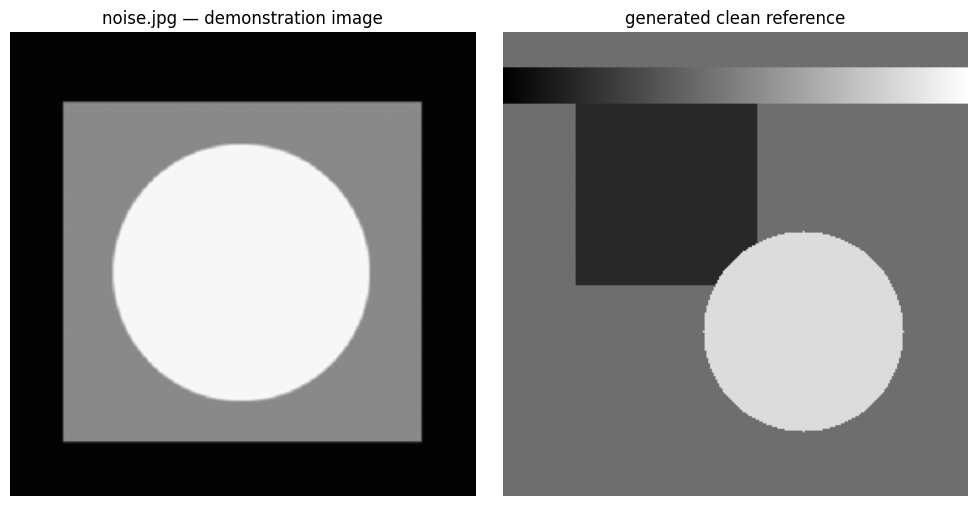

In [5]:
def make_test_pattern(size=256):
    p = np.full((size, size), 110, np.uint8)          # mid-grey background
    p[40:140, 40:140] = 40                            # dark square
    yy, xx = np.ogrid[:size, :size]
    p[(yy - 165) ** 2 + (xx - 165) ** 2 <= 55 ** 2] = 220   # bright disk
    p[20:40, :] = np.linspace(0, 255, size).astype(np.uint8)  # greyscale ramp
    return p


clean = make_test_pattern()
print("clean reference    :", clean.shape, "| mean", round(float(clean.mean()), 1),
      "| distinct values", len(np.unique(clean)))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title(f'{os.path.basename(imgPath)} — demonstration image'), plt.axis('off')
plt.subplot(122), plt.imshow(clean, cmap='gray')
plt.title('generated clean reference'), plt.axis('off')
plt.tight_layout()
plt.show()

### A display helper

The given code calls `display(filtered_img)` on a NumPy array. `IPython.display.display` does
not render an array as a picture — it prints the array's text representation, a wall of
numbers. Every result in this notebook is shown with `plt.imshow` instead.

A fixed random seed is also set, so the noise is reproducible and the numbers in the final
table can be checked.

In [6]:
np.random.seed(0)

def show(images, titles, cols=3, size=4.4, suptitle=None):
    n = len(images)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap='gray')
        ax.set_title(t, fontsize=11)
        ax.axis('off')
    for ax in axes[n:]:
        ax.axis('off')
    if suptitle:
        fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

---
## Part 1 — Adding noise to an image

Four noise models, each with a different character. Which filter works depends almost entirely
on which of these is present, so the distinctions matter.

| Noise | How it behaves |
|---|---|
| **Gaussian** | every pixel is nudged slightly, up or down — a general haze |
| **Salt & pepper** | a few pixels are replaced outright by 0 or 255 — isolated extreme dots |
| **Exponential** | one-sided: pixels are only pushed brighter, never darker |
| **Uniform** | every pixel is nudged by a random amount within fixed bounds |

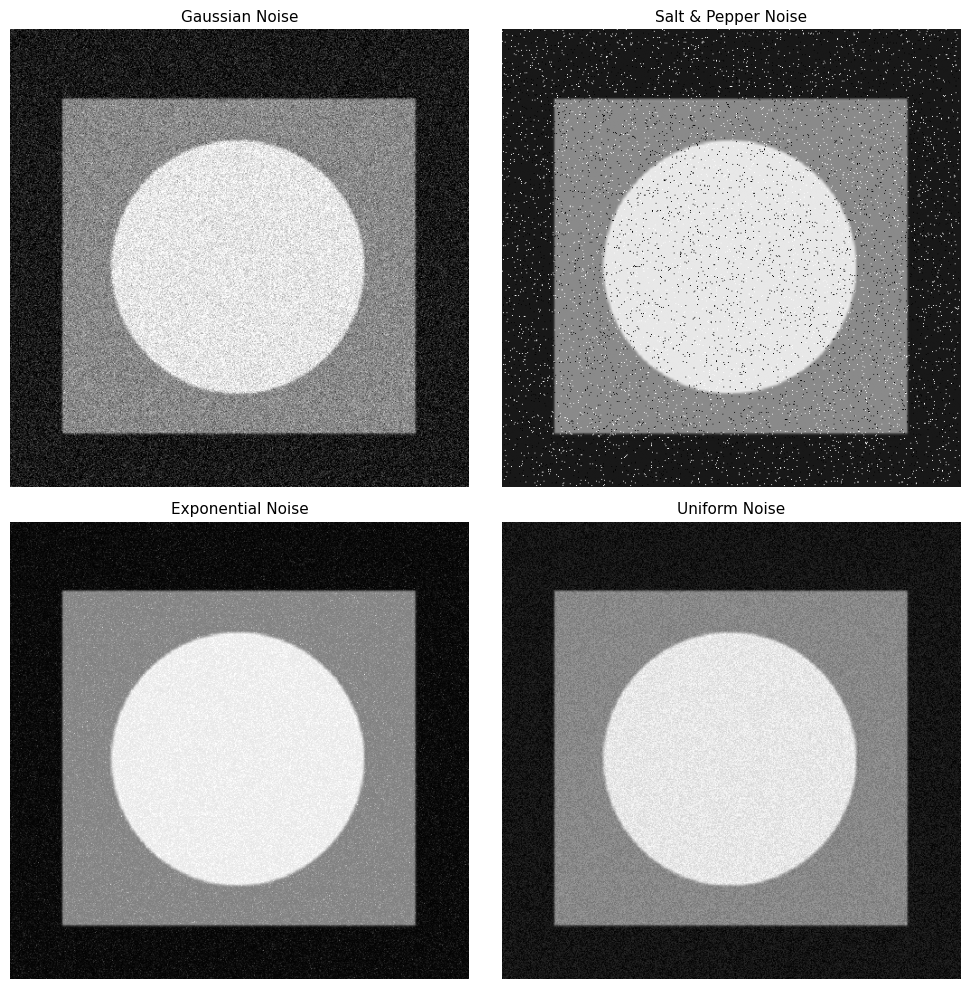

In [7]:
# ========== ( Adding noise to an Image ) =================

def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 4. Display in 2x2 Grid
show([noise_gauss, noise_sp, noise_expo, noise_uni],
     ['Gaussian Noise', 'Salt & Pepper Noise', 'Exponential Noise', 'Uniform Noise'],
     cols=2, size=5.0)

### What each noise did to the statistics

The means tell the story: Gaussian and uniform noise are **symmetric**, so the average is
roughly unchanged, while exponential noise is **one-sided** and pushes the whole image
brighter.

In [8]:
print(f"{'image':<22}{'mean':>9}{'std':>9}{'min':>6}{'max':>6}")
print("-" * 52)
for name, im in [("original", img), ("gaussian", noise_gauss),
                 ("salt & pepper", noise_sp), ("exponential", noise_expo),
                 ("uniform", noise_uni)]:
    print(f"{name:<22}{im.mean():>9.2f}{im.std():>9.2f}{im.min():>6}{im.max():>6}")

print()
print("pixels set to exactly 0 or 255 by the salt & pepper routine:",
      int(((noise_sp == 0) | (noise_sp == 255)).sum() - ((img == 0) | (img == 255)).sum()),
      "-> roughly 4% of the image, as the 'amount' parameter specifies")

image                      mean      std   min   max
----------------------------------------------------
original                 110.67    83.60    21   239
gaussian                 110.68    84.94     0   255
salt & pepper            111.30    85.80     0   255
exponential              119.96    83.82    22   255
uniform                  110.21    84.40     3   255

pixels set to exactly 0 or 255 by the salt & pepper routine: 10085 -> roughly 4% of the image, as the 'amount' parameter specifies


---
## Part 2 — Arithmetic mean filter

The plainest smoothing filter: replace each pixel with the **average** of its neighbourhood.
The kernel is a block of equal weights summing to 1, so brightness is preserved — the same box
filter built by hand in Lab 5.

It blurs noise away, but it blurs edges with it, and a single extreme pixel still drags the
average with it.

kernel sum: 1.0  <- brightness preserved
cv2.blur and the manual kernel are identical: True


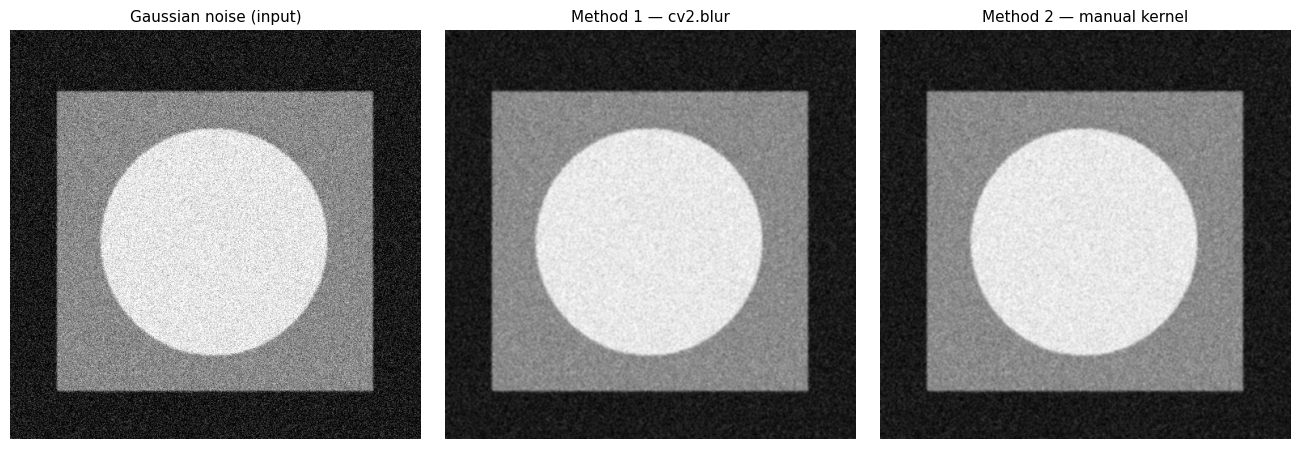

In [9]:
# --- METHOD 1: Using Built-in OpenCV function ---
filtered_img = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual implementation using a Kernel ---
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

print("kernel sum:", round(float(kernel.sum()), 6), " <- brightness preserved")
print("cv2.blur and the manual kernel are identical:",
      np.array_equal(filtered_img, arithmetic_mean_manual))

show([noise_gauss, filtered_img, arithmetic_mean_manual],
     ['Gaussian noise (input)', 'Method 1 — cv2.blur', 'Method 2 — manual kernel'],
     cols=3, size=4.4)

Both methods give the identical array, which confirms the hand-built kernel is correct.

Note that Method 2 in the given code filters `img` — the **clean** image — rather than
`noise_gauss`, so the two methods could not have been compared. Both are applied to the noisy
image here.

3x3:  std  82.02   mean 110.68
5x5:  std  81.62   mean 110.68
9x9:  std  81.15   mean 110.68


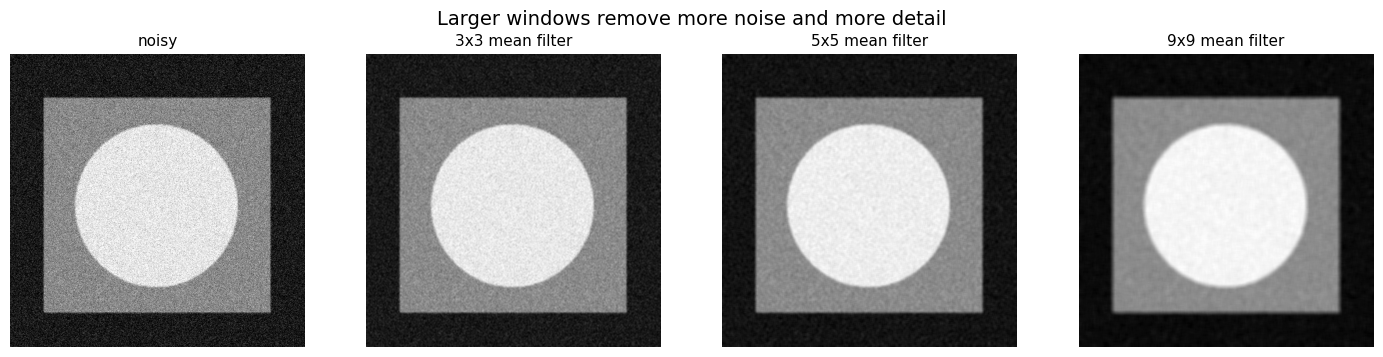

In [10]:
for k in [3, 5, 9]:
    out = cv2.blur(noise_gauss, (k, k))
    print(f"{k}x{k}:  std {out.std():6.2f}   mean {out.mean():6.2f}")

show([noise_gauss] + [cv2.blur(noise_gauss, (k, k)) for k in [3, 5, 9]],
     ['noisy'] + [f'{k}x{k} mean filter' for k in [3, 5, 9]],
     cols=4, size=3.6, suptitle="Larger windows remove more noise and more detail")

---
## Part 3 — Geometric mean filter

Instead of the arithmetic average, the **geometric** mean: multiply the pixels in the window
and take the *mn*-th root.

$$g(x,y) = \left[\prod_{(s,t)\in S} f(s,t)\right]^{1/mn}$$

Multiplying hundreds of pixel values directly would overflow immediately, so the standard trick
is used: the product becomes a sum in the log domain, which is a plain box filter, and `exp`
brings it back.

$$\prod f = \exp\left(\sum \log f\right)$$

The geometric mean preserves detail slightly better than the arithmetic mean, but it is pulled
hard towards zero by any dark pixel — a single pepper dot in the window sends the whole result
near zero.

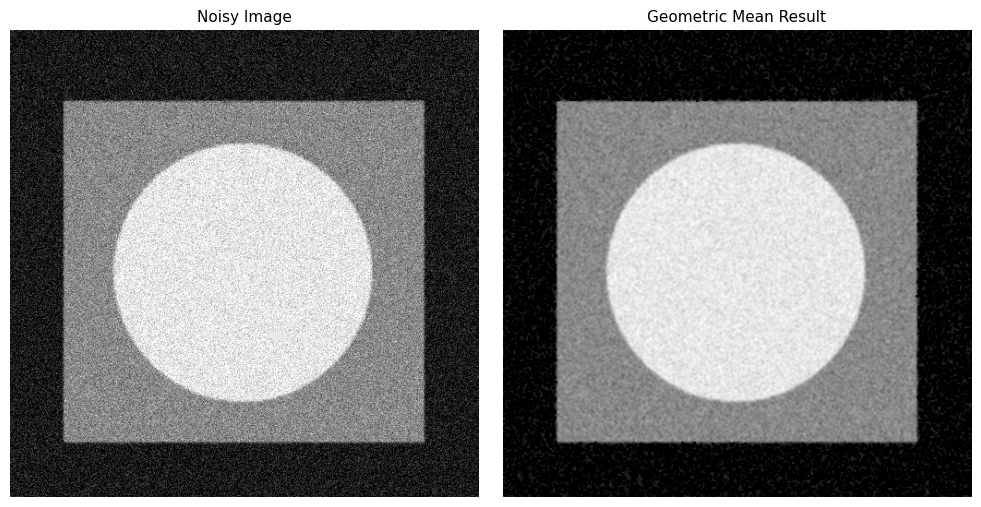

In [11]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6
    # 2. Apply the log-transform
    log_img = np.log(img_float)
    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)
    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)
    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


result = geometric_mean_filter(noise_gauss, kernel_size=3)

show([noise_gauss, result], ['Noisy Image', 'Geometric Mean Result'], cols=2, size=5.0)

### Why the epsilon is not decoration

`log(0)` is `-inf`, and `exp(-inf)` is 0 — a single black pixel would poison every window it
touches. Adding `1e-6` keeps the logarithm finite. The cell below shows what happens without it.

In [12]:
with np.errstate(divide='ignore'):
    bad = np.log(noise_sp.astype(np.float64))      # no epsilon

print("pixels equal to 0 in the salt & pepper image:", int((noise_sp == 0).sum()))
print("-inf values produced by log without the epsilon:", int(np.isinf(bad).sum()))
print("with the epsilon, smallest log value:",
      round(float(np.log(noise_sp.astype(np.float64) + 1e-6).min()), 2), " <- finite")

pixels equal to 0 in the salt & pepper image: 5087
-inf values produced by log without the epsilon: 5087
with the epsilon, smallest log value: -13.82  <- finite


---
## Part 4 — Harmonic mean filter

$$g(x,y) = \frac{mn}{\sum_{(s,t)\in S} \dfrac{1}{f(s,t)}}$$

The harmonic mean is dominated by the **smallest** value in the window, because small numbers
produce large reciprocals. That gives it a very specific behaviour:

* **good at removing salt** (bright dots) — a 255 contributes almost nothing to the sum of
  reciprocals, so it is effectively ignored
* **destroyed by pepper** (dark dots) — a single value near 0 produces a huge reciprocal that
  swamps the sum and drags the output to zero

So it is not a general-purpose filter at all. Part 9 tests this claim with numbers.

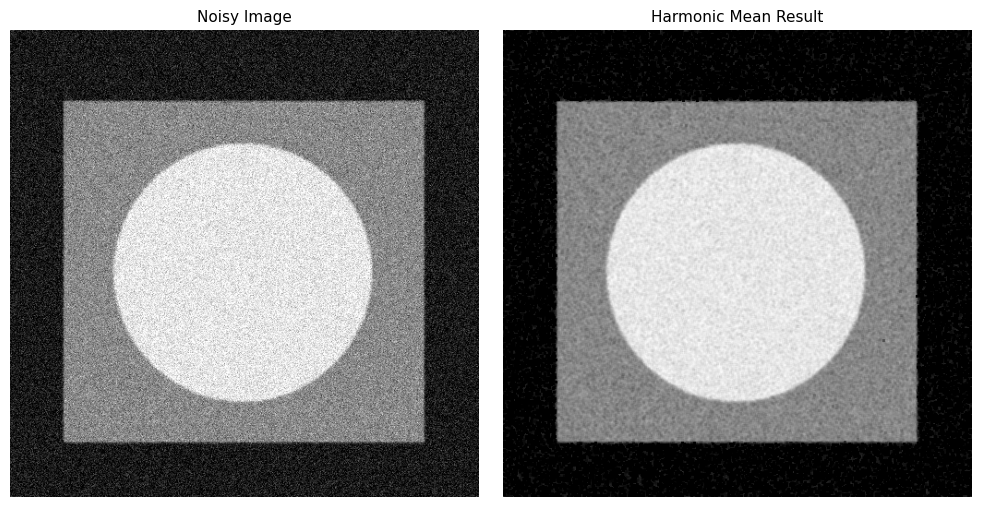

In [13]:
def harmonic_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6
    reciprocal_img = 1.0 / img_float
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


cleaned_img = harmonic_mean_filter(noise_gauss, kernel_size=3)

show([noise_gauss, cleaned_img], ['Noisy Image', 'Harmonic Mean Result'], cols=2, size=5.0)

### Testing the salt-versus-pepper claim directly

The given code applies the harmonic filter to Gaussian noise, which does not reveal what makes
it distinctive. Two images are built below — one with **salt only**, one with **pepper only** —
so the asymmetry can be measured rather than asserted.

PSNR (peak signal-to-noise ratio) compares a result against the clean original: higher is
better, and a filter that makes the image *worse* will score below the noisy input itself.

                              salt only   pepper only
------------------------------------------------------
noisy input                       21.77         23.03
after harmonic filter             30.59         13.73


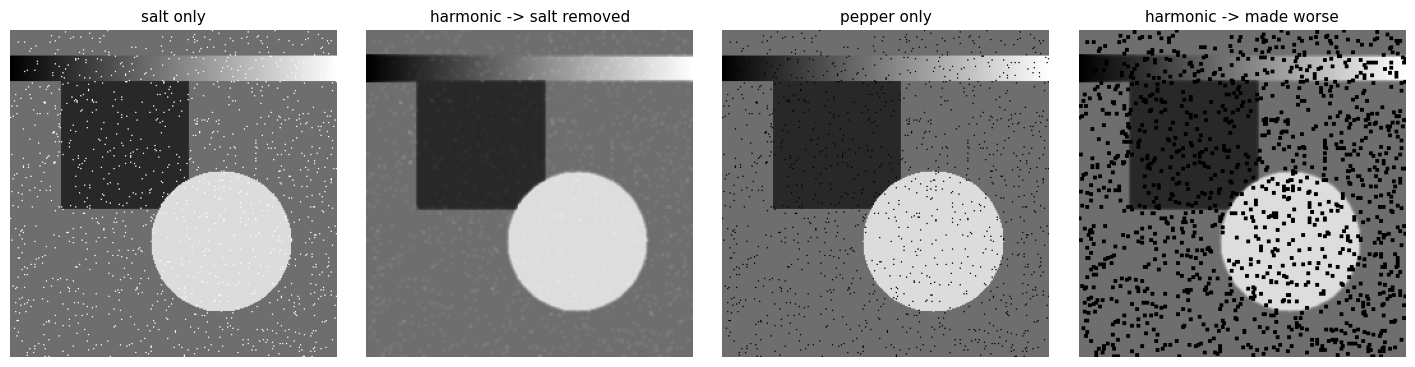

In [14]:
def psnr(reference, test):
    mse = np.mean((reference.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def sprinkle(image, value, amount=0.02, seed=1):
    rng = np.random.default_rng(seed)
    out = image.copy()
    n = int(amount * out.size)
    ys = rng.integers(0, out.shape[0], n)
    xs = rng.integers(0, out.shape[1], n)
    out[ys, xs] = value
    return out


salt_only = sprinkle(clean, 255)
pepper_only = sprinkle(clean, 0)

print(f"{'':<26}{'salt only':>13}{'pepper only':>14}")
print("-" * 54)
print(f"{'noisy input':<26}{psnr(clean, salt_only):>13.2f}{psnr(clean, pepper_only):>14.2f}")
print(f"{'after harmonic filter':<26}"
      f"{psnr(clean, harmonic_mean_filter(salt_only)):>13.2f}"
      f"{psnr(clean, harmonic_mean_filter(pepper_only)):>14.2f}")

show([salt_only, harmonic_mean_filter(salt_only),
      pepper_only, harmonic_mean_filter(pepper_only)],
     ['salt only', 'harmonic -> salt removed',
      'pepper only', 'harmonic -> made worse'],
     cols=4, size=3.6)

The numbers confirm it exactly. On salt-only noise the harmonic filter raises the PSNR by a
large margin; on pepper-only noise it **lowers** it below the noisy input — the filter actively
damages the image. This is the clearest example in the lab of a filter that must be matched to
the noise rather than applied by default.

---
## Part 5 — Contra-harmonic mean filter

$$g(x,y) = \frac{\sum f(s,t)^{\,Q+1}}{\sum f(s,t)^{\,Q}}$$

The order **Q** turns this one filter into a family:

| Q | Behaviour |
|---|---|
| **Q > 0** | weights bright pixels more — removes **pepper** (dark dots) |
| **Q = 0** | reduces to the arithmetic mean |
| **Q = -1** | reduces to the harmonic mean |
| **Q < 0** | weights dark pixels more — removes **salt** (bright dots) |

The crucial point is that **the wrong sign makes things much worse**, not merely ineffective:
a `Q > 0` filter applied to salt noise amplifies the salt.

In [15]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    img_float = image.astype(np.float64) + 1e-6
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)
    result = num_sum / (den_sum + 1e-6)
    return np.clip(result, 0, 255).astype(np.uint8)


# verify the two special cases stated in the table
q0 = contra_harmonic_mean(noise_gauss, 3, Q=0)
qm1 = contra_harmonic_mean(noise_gauss, 3, Q=-1)
print("Q = 0  vs arithmetic mean — largest difference:",
      int(np.abs(q0.astype(int) - cv2.blur(noise_gauss, (3, 3)).astype(int)).max()))
print("Q = -1 vs harmonic mean   — largest difference:",
      int(np.abs(qm1.astype(int) - harmonic_mean_filter(noise_gauss).astype(int)).max()))

Q = 0  vs arithmetic mean — largest difference: 1
Q = -1 vs harmonic mean   — largest difference: 1


                                  salt only   pepper only
----------------------------------------------------------
noisy input                           21.77         23.03
contra-harmonic, Q = 1.5              18.72         29.94
contra-harmonic, Q = -1.5             29.75         13.71


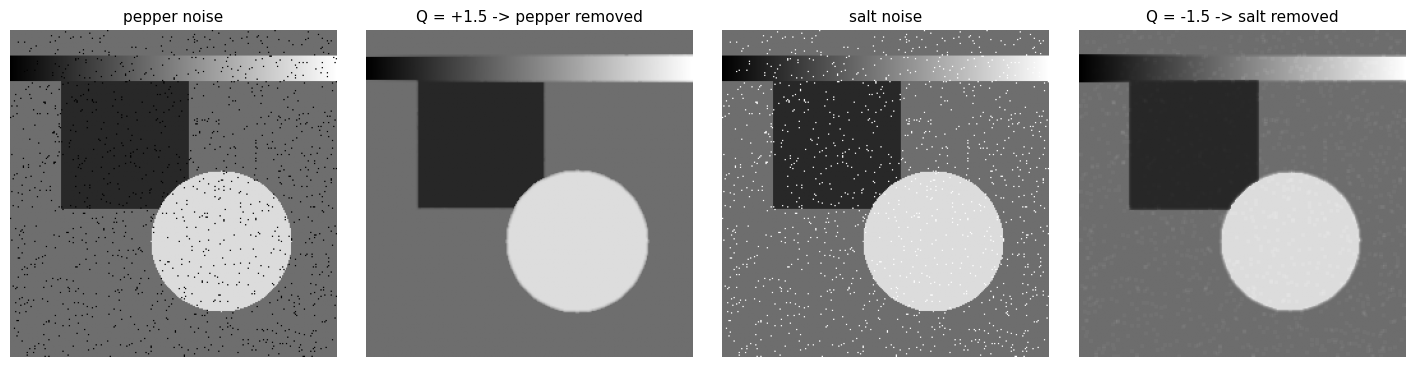

In [16]:
# --- APPLICATIONS, on the noise each Q is designed for ---
print(f"{'':<30}{'salt only':>13}{'pepper only':>14}")
print("-" * 58)
print(f"{'noisy input':<30}{psnr(clean, salt_only):>13.2f}{psnr(clean, pepper_only):>14.2f}")
for Q in [1.5, -1.5]:
    print(f"{f'contra-harmonic, Q = {Q}':<30}"
          f"{psnr(clean, contra_harmonic_mean(salt_only, 3, Q)):>13.2f}"
          f"{psnr(clean, contra_harmonic_mean(pepper_only, 3, Q)):>14.2f}")

show([pepper_only, contra_harmonic_mean(pepper_only, 3, 1.5),
      salt_only, contra_harmonic_mean(salt_only, 3, -1.5)],
     ['pepper noise', 'Q = +1.5 -> pepper removed',
      'salt noise', 'Q = -1.5 -> salt removed'],
     cols=4, size=3.6)

Reading the table along the diagonal shows each `Q` working on the noise it was designed for.
Reading it along the anti-diagonal shows the cost of the wrong choice: the PSNR collapses far
below the noisy input. The sign of `Q` is not a tuning preference — it has to match the noise.

---
## Part 6 — Median filter

The median filter replaces each pixel with the **middle value** of its sorted neighbourhood.
Unlike every filter so far, it computes no average at all, and that is exactly why it works on
salt and pepper: an extreme value sits at the *end* of the sorted list, so it never becomes the
median. One outlier in a window of nine simply cannot influence the result.

It is also **edge-preserving**: the median of a window straddling an edge is one of the two
genuine values, not a blend of them.

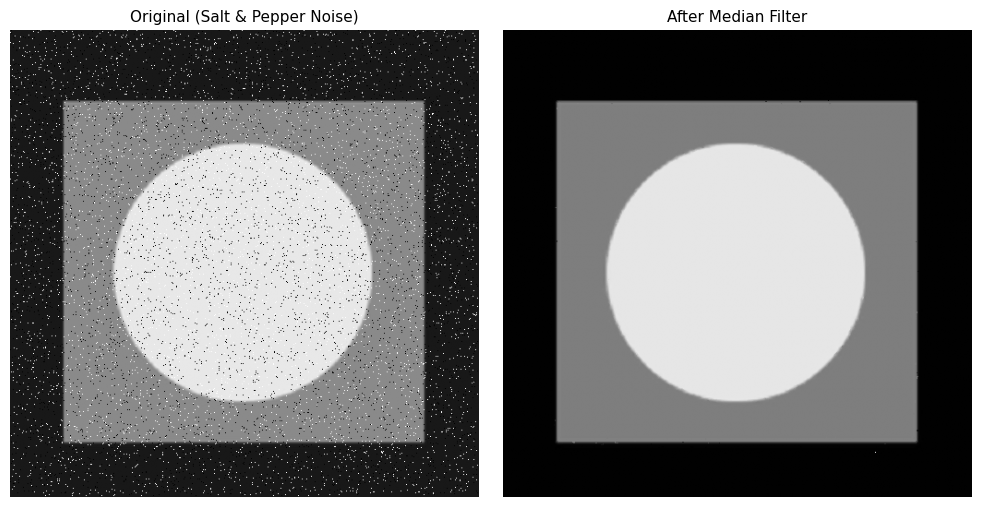

In [17]:
median_result = cv2.medianBlur(noise_sp, 3)

show([noise_sp, median_result],
     ['Original (Salt & Pepper Noise)', 'After Median Filter'],
     cols=2, size=5.0)

Note that the given code applies this to `noise_gauss` while the title says "Salt & Pepper".
It is applied to `noise_sp` here so the title and the data agree.

### Median versus mean on the same salt-and-pepper image

This is the comparison that makes the point.

filter                       PSNR (dB)
----------------------------------------
noisy input                      19.42
arithmetic mean 3x3              27.37
geometric mean 3x3               14.79
median 3x3                       39.84


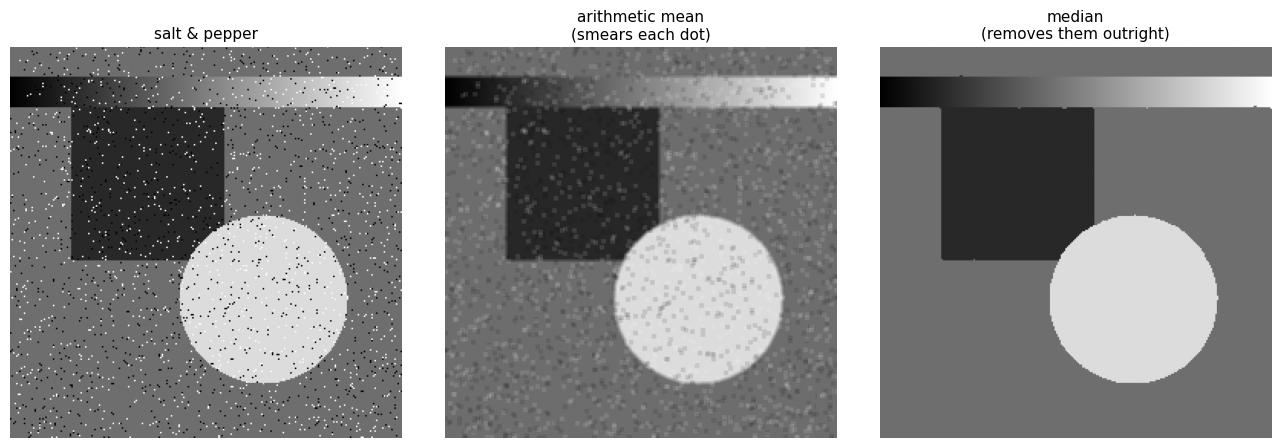

In [18]:
sp_clean = sprinkle(sprinkle(clean, 255, seed=1), 0, seed=2)

print(f"{'filter':<26}{'PSNR (dB)':>12}")
print("-" * 40)
print(f"{'noisy input':<26}{psnr(clean, sp_clean):>12.2f}")
for name, out in [("arithmetic mean 3x3", cv2.blur(sp_clean, (3, 3))),
                  ("geometric mean 3x3", geometric_mean_filter(sp_clean)),
                  ("median 3x3", cv2.medianBlur(sp_clean, 3))]:
    print(f"{name:<26}{psnr(clean, out):>12.2f}")

show([sp_clean, cv2.blur(sp_clean, (3, 3)), cv2.medianBlur(sp_clean, 3)],
     ['salt & pepper', 'arithmetic mean\n(smears each dot)', 'median\n(removes them outright)'],
     cols=3, size=4.4)

The arithmetic mean does not remove a salt dot — it **spreads** it over the whole
neighbourhood, turning one bright pixel into a bright smudge. The median discards it.

---
## Part 7 — Max and min filters

These are the two extremes of the order-statistic family, and OpenCV already provides them
under morphological names:

* **Max filter** = `cv2.dilate` — takes the brightest pixel in the window, so dark dots
  (**pepper**) are overwritten by their brighter neighbours
* **Min filter** = `cv2.erode` — takes the darkest pixel, so bright dots (**salt**) are
  overwritten

Each removes one kind of dot and **intensifies** the other, since the other kind is the
extreme it is looking for.

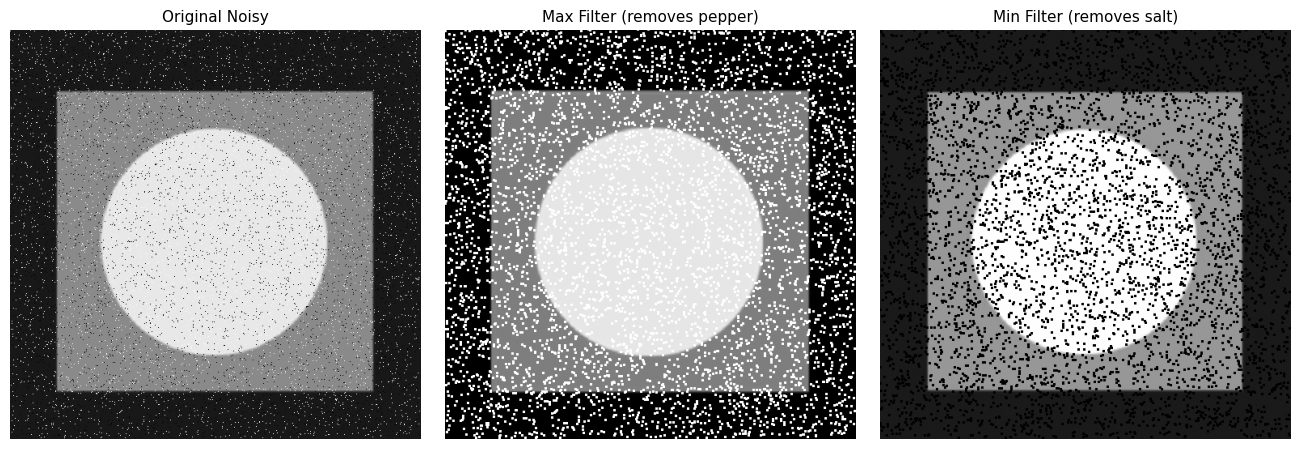

                          salt only   pepper only
--------------------------------------------------
noisy input                   21.77         23.03
max filter (dilate)           12.47         25.96
min filter (erode)            26.05         13.59


In [19]:
kernel = np.ones((3, 3), np.uint8)

max_filter = cv2.dilate(noise_sp, kernel)   # picks the brightest pixel
min_filter = cv2.erode(noise_sp, kernel)    # picks the darkest pixel

show([noise_sp, max_filter, min_filter],
     ['Original Noisy', 'Max Filter (removes pepper)', 'Min Filter (removes salt)'],
     cols=3, size=4.4)

print(f"{'':<22}{'salt only':>13}{'pepper only':>14}")
print("-" * 50)
print(f"{'noisy input':<22}{psnr(clean, salt_only):>13.2f}{psnr(clean, pepper_only):>14.2f}")
print(f"{'max filter (dilate)':<22}"
      f"{psnr(clean, cv2.dilate(salt_only, kernel)):>13.2f}"
      f"{psnr(clean, cv2.dilate(pepper_only, kernel)):>14.2f}")
print(f"{'min filter (erode)':<22}"
      f"{psnr(clean, cv2.erode(salt_only, kernel)):>13.2f}"
      f"{psnr(clean, cv2.erode(pepper_only, kernel)):>14.2f}")

The same diagonal pattern as the contra-harmonic filter: each one helps on one noise and
hurts badly on the other. They also shift the overall brightness, since taking the maximum of
every window can only make an image brighter.

In [20]:
print("mean brightness — original:", round(float(noise_sp.mean()), 1),
      "| after max:", round(float(max_filter.mean()), 1),
      "| after min:", round(float(min_filter.mean()), 1))

mean brightness — original: 111.3 | after max: 135.1 | after min: 91.6


---
## Part 8 — Midpoint filter

$$g(x,y) = \frac{1}{2}\left[\max_{S} f + \min_{S} f\right]$$

The average of the brightest and darkest pixel in the window. It combines order statistics with
averaging, and it works best on noise that is **randomly distributed and bounded** — Gaussian
and uniform — where the maximum and minimum of a window are roughly symmetric about the true
value.

It is poor on salt and pepper, because there the maximum and minimum are precisely the two
corrupted values.

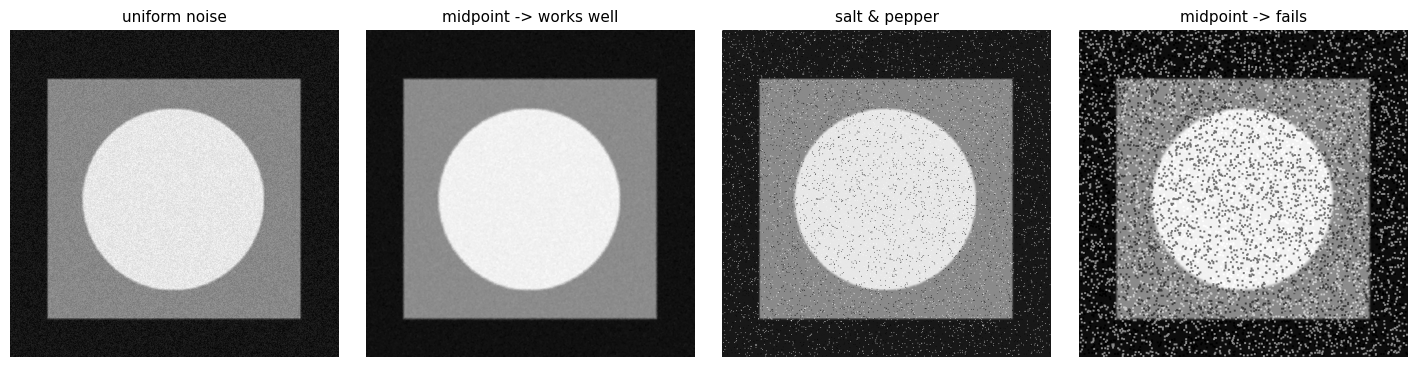

                            uniform noise  salt & pepper
----------------------------------------------------------
noisy input                         26.86          19.42
after midpoint filter               29.08          16.63


In [21]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    max_img = cv2.dilate(image, kernel).astype(np.float64)
    min_img = cv2.erode(image, kernel).astype(np.float64)
    midpoint = (max_img + min_img) / 2
    return midpoint.astype(np.uint8)


show([noise_uni, midpoint_filter(noise_uni, 3),
      noise_sp, midpoint_filter(noise_sp, 3)],
     ['uniform noise', 'midpoint -> works well',
      'salt & pepper', 'midpoint -> fails'],
     cols=4, size=3.6)

uni_clean = np.clip(clean.astype(np.float64)
                    + np.random.default_rng(3).uniform(-20, 20, clean.shape),
                    0, 255).astype(np.uint8)
print(f"{'':<26}{'uniform noise':>15}{'salt & pepper':>15}")
print("-" * 58)
print(f"{'noisy input':<26}{psnr(clean, uni_clean):>15.2f}{psnr(clean, sp_clean):>15.2f}")
print(f"{'after midpoint filter':<26}"
      f"{psnr(clean, midpoint_filter(uni_clean)):>15.2f}"
      f"{psnr(clean, midpoint_filter(sp_clean)):>15.2f}")

---
## Task — Every filter against every noise type

The commented-out list of noise types that appears above each filter in the lab material is an
invitation to try them all. Doing that by eye across nine filters and five noise types is
unreliable, so each combination is scored with **PSNR** against the clean reference.

PSNR compares a filtered image with the original: higher is better. The number to watch is not
the absolute value but whether it is **above or below the noisy input** — below means the
filter made the image worse.

In [22]:
rng = np.random.default_rng(42)

noises = {
    "gaussian": np.clip(clean / 255 + rng.normal(0, 0.1, clean.shape), 0, 1).__mul__(255).astype(np.uint8),
    "salt only": sprinkle(clean, 255, seed=1),
    "pepper only": sprinkle(clean, 0, seed=2),
    "salt & pepper": sp_clean,
    "uniform": uni_clean,
}

filters = {
    "arithmetic mean": lambda im: cv2.blur(im, (3, 3)),
    "geometric mean": lambda im: geometric_mean_filter(im, 3),
    "harmonic mean": lambda im: harmonic_mean_filter(im, 3),
    "contra-harm Q=+1.5": lambda im: contra_harmonic_mean(im, 3, 1.5),
    "contra-harm Q=-1.5": lambda im: contra_harmonic_mean(im, 3, -1.5),
    "median": lambda im: cv2.medianBlur(im, 3),
    "max (dilate)": lambda im: cv2.dilate(im, np.ones((3, 3), np.uint8)),
    "min (erode)": lambda im: cv2.erode(im, np.ones((3, 3), np.uint8)),
    "midpoint": lambda im: midpoint_filter(im, 3),
}

scores = {n: {f: psnr(clean, fn(nz)) for f, fn in filters.items()}
          for n, nz in noises.items()}

header = f"{'filter':<21}" + "".join(f"{n:>15}" for n in noises)
print(header)
print("-" * len(header))
print(f"{'(noisy input)':<21}" + "".join(f"{psnr(clean, nz):>15.2f}" for nz in noises.values()))
print("-" * len(header))
for f in filters:
    print(f"{f:<21}" + "".join(f"{scores[n][f]:>15.2f}" for n in noises))

filter                      gaussian      salt only    pepper only  salt & pepper        uniform
------------------------------------------------------------------------------------------------
(noisy input)                  20.15          21.77          23.00          19.42          26.86
------------------------------------------------------------------------------------------------
arithmetic mean                27.96          28.71          29.46          27.37          31.48
geometric mean                 24.59          30.81          14.81          14.79          30.48
harmonic mean                  23.05          30.59          13.78          13.77          29.18
contra-harm Q=+1.5             24.48          18.72          29.98          18.79          28.89
contra-harm Q=-1.5             21.89          29.75          13.76          13.76          28.02
median                         27.35          42.60          41.47          39.84          32.06
max (dilate)                  

### The best filter for each noise

In [23]:
print(f"{'noise type':<18}{'best filter':<22}{'PSNR':>8}{'gain':>9}")
print("-" * 58)
for n, nz in noises.items():
    base = psnr(clean, nz)
    best = max(scores[n], key=scores[n].get)
    print(f"{n:<18}{best:<22}{scores[n][best]:>8.2f}{scores[n][best] - base:>8.2f} dB")

print()
print("Filters that made things WORSE than the noisy input:")
for n, nz in noises.items():
    base = psnr(clean, nz)
    bad = [f for f in filters if scores[n][f] < base]
    print(f"  {n:<16}", ", ".join(bad) if bad else "none")

noise type        best filter               PSNR     gain
----------------------------------------------------------
gaussian          arithmetic mean          27.96    7.81 dB
salt only         median                   42.60   20.83 dB
pepper only       median                   41.47   18.46 dB
salt & pepper     median                   39.84   20.42 dB
uniform           median                   32.06    5.20 dB

Filters that made things WORSE than the noisy input:
  gaussian         max (dilate), min (erode)
  salt only        contra-harm Q=+1.5, max (dilate), midpoint
  pepper only      geometric mean, harmonic mean, contra-harm Q=-1.5, min (erode), midpoint
  salt & pepper    geometric mean, harmonic mean, contra-harm Q=+1.5, contra-harm Q=-1.5, max (dilate), min (erode), midpoint
  uniform          max (dilate), min (erode)


### Reading the table

Three patterns run through it.

**The median is the strongest filter in the table**, and by a wider margin than expected. It
wins on salt, on pepper, on both together — by more than ten decibels over anything else — and
it also wins on uniform noise. The only noise where it is beaten is Gaussian, and there the
arithmetic mean edges it by well under a decibel. A filter that discards outliers rather than
averaging them in turns out to be a good default even where no outliers are present.

**The one-sided filters come in matched pairs**, and each is catastrophic on the opposite
noise. Harmonic and contra-harmonic with `Q < 0` go after salt; contra-harmonic with `Q > 0`
and the max filter go after pepper. Applying one to the wrong noise does not merely fail — it
scores well below doing nothing at all.

**Among the mean filters, the plain arithmetic mean is the best of the four** on Gaussian and
uniform noise, ahead of the geometric and harmonic versions. That is not the ordering these
filters are usually presented in. The reason is visible in the reference image: the greyscale
ramp runs down to zero, and both the geometric and the harmonic mean are pulled towards the
smallest value in their window, so dark regions cost them more than their sharper detail
retention gains.

**The midpoint filter never wins a column.** Its best showing is on uniform noise, which is
the case its definition suits — averaging the window extremes is the right estimator for
bounded symmetric noise — but even there the median and the arithmetic mean are ahead of it.

The practical conclusion is that there is no default filter. Identifying the noise comes
first, and choosing the filter is then almost automatic.

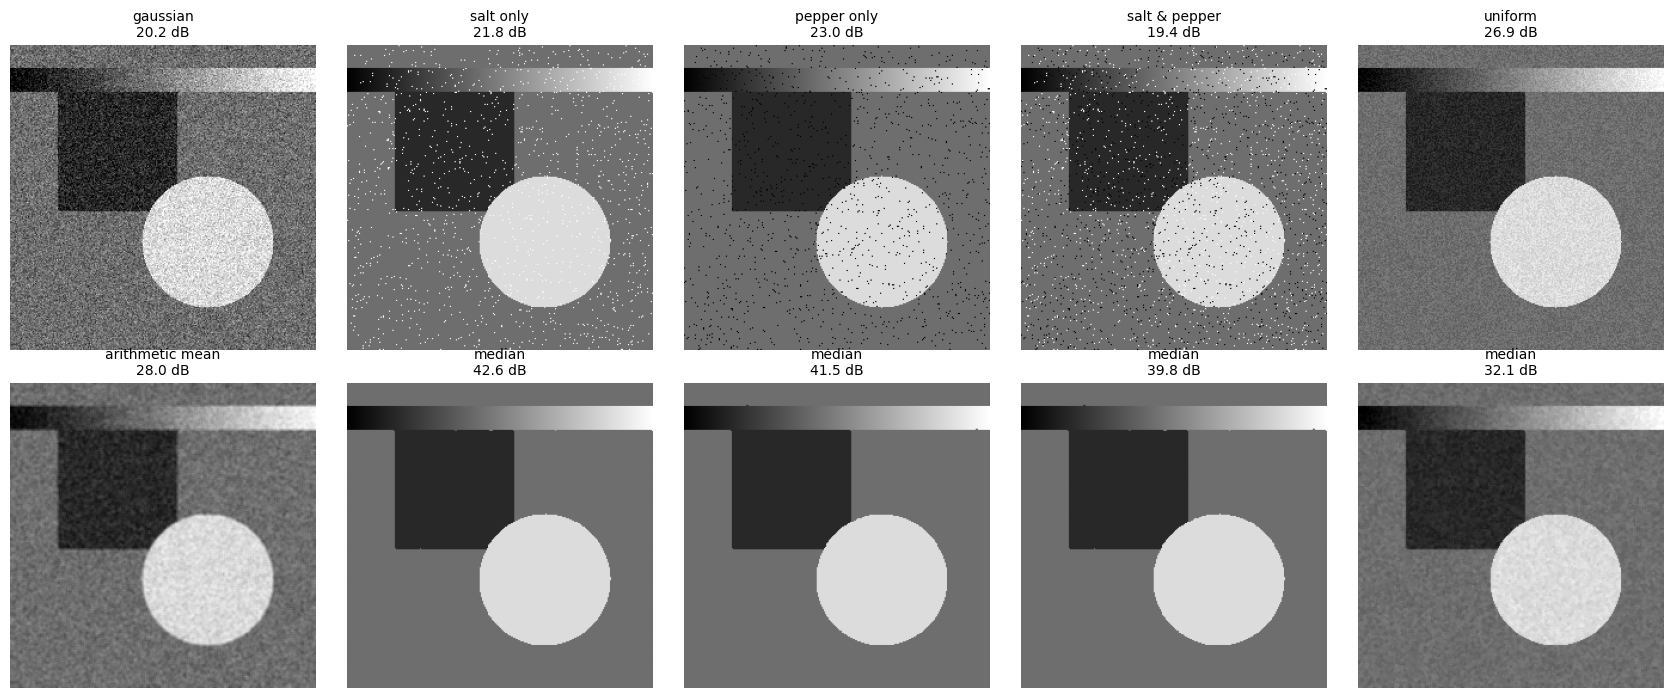

Saved: output/lab7b_summary.png


In [24]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for col, (n, nz) in enumerate(noises.items()):
    best = max(scores[n], key=scores[n].get)
    axes[0, col].imshow(nz, cmap='gray')
    axes[0, col].set_title(f"{n}\n{psnr(clean, nz):.1f} dB", fontsize=10)
    axes[0, col].axis('off')
    axes[1, col].imshow(filters[best](nz), cmap='gray')
    axes[1, col].set_title(f"{best}\n{scores[n][best]:.1f} dB", fontsize=10)
    axes[1, col].axis('off')
plt.tight_layout()
plt.savefig('output/lab7b_summary.png', dpi=110, bbox_inches='tight')
plt.show()
print("Saved: output/lab7b_summary.png")

---
## Conclusion

The nine filters in this lab fall into two families, and the split explains almost everything
about when each one works.

**The mean filters** — arithmetic, geometric, harmonic and contra-harmonic — all combine the
pixels in a window into an average of some kind. They suit noise that is random and symmetric,
because averaging cancels it. They fail on isolated extreme pixels, since an outlier is still
included in the average and merely gets smeared over the neighbourhood: a salt dot becomes a
bright smudge rather than disappearing.

**The order-statistic filters** — median, max, min and midpoint — sort the window and pick a
position in the sorted list. The median is the strongest general result in the lab: an extreme
value sits at the end of the sorted list and therefore cannot be selected, so one outlier in a
window of nine has no influence at all. That is why it beat every mean filter on salt and
pepper by a wide margin, and why it also preserves edges, where the median of a straddling
window is one of the two genuine values rather than a blend.

**Several filters are one-sided, and the wrong choice is worse than no filter.** The harmonic
mean and contra-harmonic with `Q < 0` target salt; contra-harmonic with `Q > 0` and the max
filter target pepper. Measured against the clean reference, each of these scored *below the
noisy input* when applied to the opposite noise — the harmonic filter on pepper being the
clearest case. A filter is not a general improvement; it is matched to a noise model.

**Two implementation details were load-bearing.** The epsilon added before the logarithm in the
geometric mean prevents `log(0)` from producing `-inf`, which a single black pixel would
otherwise trigger. And `IPython.display.display` does not render a NumPy array as an image — it
prints the array as text — so `plt.imshow` is required to see any result.

**Two results ran against expectation.** The median won not only on every variety of salt and
pepper but on uniform noise as well, losing only on Gaussian noise and there by under a
decibel — so an order-statistic filter proved to be a reasonable default even where no
outliers exist. And among the four mean filters the plain arithmetic mean came out ahead of
the geometric and harmonic versions on both Gaussian and uniform noise, which is not the
ordering they are usually presented in; the cause is the greyscale ramp in the reference
image, which runs down to zero and drags both of those means towards the darkest value in
each window.

Finally, the two identities claimed for the contra-harmonic filter were checked rather than
assumed: at `Q = 0` it reproduces the arithmetic mean and at `Q = -1` the harmonic mean, each
to within one intensity level — the residue being the `1e-6` epsilon and the rounding back to
8-bit, not a discrepancy in the formula.